# 02 — Protein vs. its own gene's RNA: overall and within cell types

For each protein we correlate its CLR value with the RNA (log1p CP10k) of the gene(s) it is
mapped to:

* **overall**: across all cells
* **within cell type**: inside each cell type with >= 50 cells, then summarized per protein
  (cell-weighted mean, unweighted mean, median)
* **between cell types**: correlation of cell-type means (pseudo-bulk)
* **within cell type x sample**: controls for the site/sample effect found in Phase 1

Design decisions fixed **before** looking at full-data results:
* The protein-gene map and its analysis sets (`resources/protein_gene_map.csv`) are frozen.
  Headline numbers use the **primary** set (110 proteins); the **secondary** set (7) is
  reported separately; 17 proteins have no measured gene.
* Pearson is the main metric. Spearman is run as a sensitivity analysis because RNA is very
  sparse (many tied zeros).
* A mapping diagnostic (rank of the mapped gene among all genes) is reported to catch obvious
  mapping errors. It is **not** used to change or choose mappings.
* No model is trained here, so using all cells is not leakage.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

from citeseq.paths import CITE_H5AD, REPO_ROOT, RESULTS_DIR, FIGURES_DIR
from citeseq.io import load_cite, _read_dataframe
from citeseq.correlation import (load_protein_gene_map, mapped_log_expression, corr_columns,
                                 within_group_pearson, summarize_within, between_group_pearson,
                                 correlate_with_all_genes, mapped_gene_rank)
from citeseq import plotting as P
import h5py

P.set_style()
MIN_CELLS = 50          # minimum cells for a group (cell type, or cell type x sample)
pd.set_option("display.float_format", "{:.3f}".format)

## 1. Load RNA counts, protein CLR and the frozen mapping

In [2]:
with h5py.File(CITE_H5AD) as f:
    var = _read_dataframe(f["var"])
t0 = time.time()
rna = load_cite(CITE_H5AD, "layers/counts", var_mask=(var["feature_types"] == "GEX").to_numpy())
adt = load_cite(CITE_H5AD, "X", var_mask=(var["feature_types"] == "ADT").to_numpy())
assert (rna.obs_names == adt.obs_names).all()
print(f"loaded in {time.time() - t0:.0f}s:", rna.shape, adt.shape)

pmap = load_protein_gene_map(REPO_ROOT / "resources/protein_gene_map.csv", rna.var_names)
print(pmap["analysis_set"].value_counts().to_string())
assert (pmap["usable"] == (pmap["analysis_set"] != "unavailable")).all()
use = pmap[pmap["usable"]].reset_index(drop=True)

loaded in 13s: (90261, 13953) (90261, 134)
analysis_set
primary        110
unavailable     17
secondary        7


## 2. RNA value per protein

Raw counts of the mapped gene(s) are summed, divided by the cell's total RNA counts (all
13,953 genes), multiplied by 10,000 and log1p-transformed.

In [3]:
total = np.asarray(rna.X.sum(axis=1)).ravel()
R = mapped_log_expression(rna.X, rna.var_names, total, use["gene_list"].tolist())
Pm = adt[:, use["protein"].tolist()].X.toarray().astype(np.float32)

# share of cells in which the mapped RNA was detected at all (>= 1 count)
use["rna_detected_frac"] = (R > 0).mean(axis=0)
use["protein_mean_clr"] = Pm.mean(axis=0)
cell_type = rna.obs["cell_type"].astype(str).to_numpy()
type_sample = (rna.obs["cell_type"].astype(str) + " | " + rna.obs["batch"].astype(str)).to_numpy()
print(R.shape, Pm.shape)

(90261, 117) (90261, 117)


## 3. Correlations

In [4]:
res = use[["protein", "genes", "mapping_type", "analysis_set", "rna_detected_frac", "protein_mean_clr"]].copy()
for method in ["pearson", "spearman"]:
    res[f"{method}_all"] = corr_columns(R, Pm, method)
    w = summarize_within(within_group_pearson(R, Pm, cell_type, MIN_CELLS, method), len(use))
    res[f"{method}_within_w"] = w["weighted_mean"].to_numpy()
    res[f"{method}_within_unw"] = w["mean"].to_numpy()
    res[f"{method}_within_median"] = w["median"].to_numpy()
    if method == "pearson":
        res["n_types"] = w["n_groups"].to_numpy()
        res["n_types_nan"] = w["n_groups_nan"].to_numpy()
    ts = summarize_within(within_group_pearson(R, Pm, type_sample, MIN_CELLS, method), len(use))
    res[f"{method}_within_type_sample_w"] = ts["weighted_mean"].to_numpy()

r_between, n_types_between = between_group_pearson(R, Pm, cell_type, MIN_CELLS)
res["pearson_between_types"] = r_between
n_types_used = pd.Series(cell_type).value_counts().ge(MIN_CELLS).sum()
n_ts_used = pd.Series(type_sample).value_counts().ge(MIN_CELLS).sum()
print(f"cell types with >= {MIN_CELLS} cells: {n_types_used}; cell type x sample groups: {n_ts_used}")
print("proteins with a cell type where r is undefined (gene or protein constant):", (res["n_types_nan"] > 0).sum())

cell types with >= 50 cells: 42; cell type x sample groups: 296
proteins with a cell type where r is undefined (gene or protein constant): 58


## 4. Summary: primary set (headline) and secondary set (separate)

In [5]:
cols = ["pearson_all", "pearson_between_types", "pearson_within_w", "pearson_within_unw",
        "pearson_within_median", "pearson_within_type_sample_w",
        "spearman_all", "spearman_within_w", "spearman_within_type_sample_w"]
prim = res[res["analysis_set"] == "primary"]
summary = pd.DataFrame({
    "median": prim[cols].median(),
    "q25": prim[cols].quantile(0.25),
    "q75": prim[cols].quantile(0.75),
})
print(f"PRIMARY set, n = {len(prim)} proteins (distribution across proteins)")
summary

PRIMARY set, n = 110 proteins (distribution across proteins)


,median,q25,q75
pearson_all,0.291,0.140,0.450
pearson_between_types,0.836,0.607,0.937
pearson_within_w,0.072,0.036,0.118
pearson_within_unw,0.097,0.043,0.145
pearson_within_median,0.069,0.028,0.121
pearson_within_type_sample_w,0.062,0.036,0.099
spearman_all,0.240,0.137,0.362
spearman_within_w,0.064,0.038,0.097
spearman_within_type_sample_w,0.050,0.031,0.079


In [6]:
print("Paired difference overall - within (cell-weighted), primary set:")
diff = prim["pearson_all"] - prim["pearson_within_w"]
print(f"  median {diff.median():.3f}; within < overall for {(diff > 0).sum()} of {len(prim)} proteins")
print("Within type vs within type x sample (cell-weighted), primary set:")
d2 = prim["pearson_within_w"] - prim["pearson_within_type_sample_w"]
print(f"  median difference {d2.median():.3f}")

Paired difference overall - within (cell-weighted), primary set:
  median 0.195; within < overall for 100 of 110 proteins
Within type vs within type x sample (cell-weighted), primary set:
  median difference 0.006


In [7]:
print("SECONDARY set (not part of the headline)")
res[res["analysis_set"] == "secondary"][["protein", "genes", "pearson_all", "pearson_between_types",
                                          "pearson_within_w", "spearman_within_w", "rna_detected_frac"]]

SECONDARY set (not part of the headline)


,protein,genes,pearson_all,pearson_between_types,pearson_within_w,spearman_within_w,rna_detected_frac
16,CD45RA,PTPRC,0.136,0.360,0.013,-0.030,0.744
25,CD16,FCGR3A,0.635,0.843,0.167,0.084,0.129
27,CD45RO,PTPRC,0.179,0.456,0.064,0.062,0.744
35,CD32,FCGR2A;FCGR2B,0.479,0.769,0.160,0.148,0.165
46,CD107a,LAMP1,0.055,-0.220,0.051,0.066,0.245
91,CD45,PTPRC,0.484,0.897,0.166,0.125,0.744
96,CD63,CD63,0.371,0.661,0.100,0.087,0.483


## 5. Figures

Overall vs. within-cell-type correlation per protein. Points below the diagonal lose
correlation once cell-type identity is held fixed.

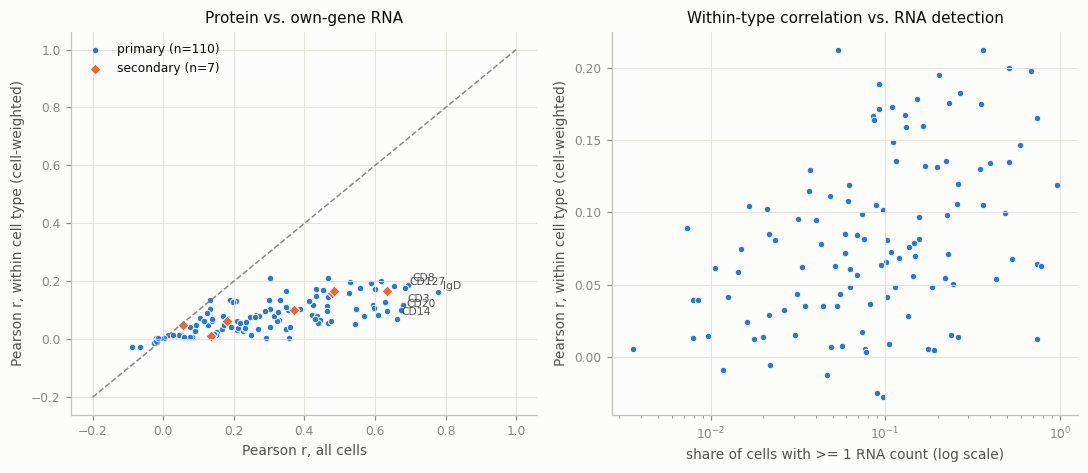

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
ax = axes[0]
sec = res["analysis_set"] == "secondary"
ax.plot([-0.2, 1], [-0.2, 1], color=P.MUTED, lw=1, ls="--")
ax.scatter(res.loc[~sec, "pearson_all"], res.loc[~sec, "pearson_within_w"], s=18, c=P.BLUE,
           label=f"primary (n={int((~sec).sum())})", edgecolors=P.SURFACE, linewidths=0.6)
ax.scatter(res.loc[sec, "pearson_all"], res.loc[sec, "pearson_within_w"], s=26, c=P.ORANGE, marker="D",
           label=f"secondary (n={int(sec.sum())})", edgecolors=P.SURFACE, linewidths=0.6)
for _, row in res.sort_values("pearson_all", ascending=False).head(6).iterrows():
    ax.annotate(row["protein"], (row["pearson_all"], row["pearson_within_w"]), fontsize=7,
                color=P.INK_2, xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("Pearson r, all cells"); ax.set_ylabel("Pearson r, within cell type (cell-weighted)")
ax.set_title("Protein vs. own-gene RNA")
ax.legend(frameon=False, fontsize=8, loc="upper left")

ax = axes[1]
ax.scatter(res["rna_detected_frac"], res["pearson_within_w"], s=18, c=P.BLUE, edgecolors=P.SURFACE, linewidths=0.6)
ax.set_xscale("log")
ax.set_xlabel("share of cells with >= 1 RNA count (log scale)")
ax.set_ylabel("Pearson r, within cell type (cell-weighted)")
ax.set_title("Within-type correlation vs. RNA detection")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase2_overall_vs_within.png")

Three example proteins, chosen by a fixed rule (not by eye), all from the primary set:
the largest drop from overall to within, the highest within-type r, and the lowest overall r.
Grey: cells (random 20,000). Blue: cell-type means (types with >= 50 cells).

['IgD', 'CD9', 'CD115']

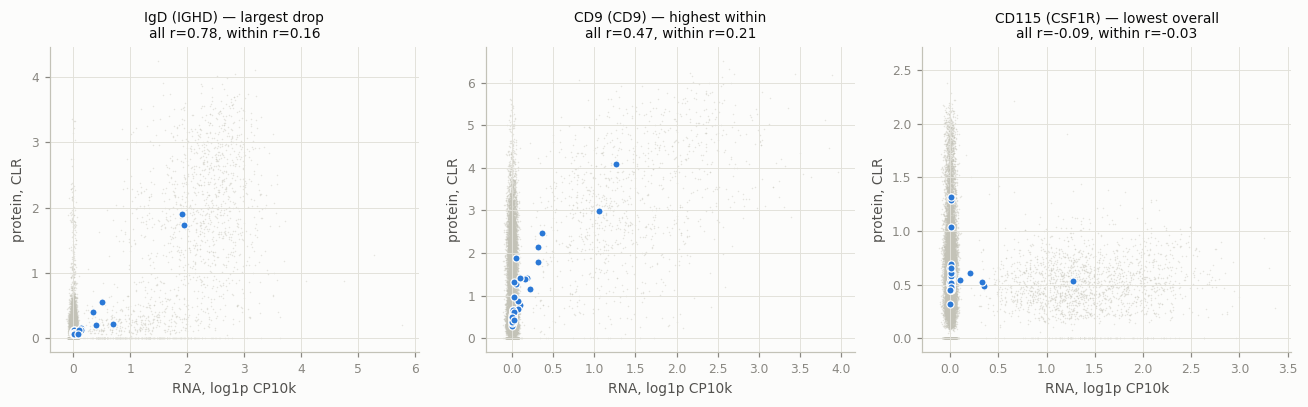

In [9]:
rng = np.random.default_rng(0)
sub = rng.choice(len(R), size=min(20_000, len(R)), replace=False)
p = prim.assign(drop=prim["pearson_all"] - prim["pearson_within_w"])
examples = [p.loc[p["drop"].idxmax(), "protein"], p.loc[p["pearson_within_w"].idxmax(), "protein"],
            p.loc[p["pearson_all"].idxmin(), "protein"]]
labels = ["largest drop", "highest within", "lowest overall"]
big_types = pd.Series(cell_type).value_counts()
big_types = big_types.index[big_types >= MIN_CELLS]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, prot, lab in zip(axes, examples, labels):
    j = int(use.index[use["protein"] == prot][0])
    row = res.iloc[j]
    jit = rng.normal(0, 0.03, size=sub.size)  # small jitter: RNA values are discrete
    ax.scatter(R[sub, j] + jit, Pm[sub, j], s=1, c=P.CONTEXT, alpha=0.4, linewidths=0, rasterized=True)
    means = pd.DataFrame({"r": R[:, j], "p": Pm[:, j], "t": cell_type}).groupby("t").mean().loc[big_types]
    ax.scatter(means["r"], means["p"], s=22, c=P.BLUE, edgecolors=P.SURFACE, linewidths=0.8, zorder=3)
    ax.set_title(f"{prot} ({row['genes']}) — {lab}\nall r={row['pearson_all']:.2f}, "
                 f"within r={row['pearson_within_w']:.2f}", fontsize=9)
    ax.set_xlabel("RNA, log1p CP10k"); ax.set_ylabel("protein, CLR")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase2_examples.png")
examples

Spearman - Pearson (within, weighted), primary: median -0.005


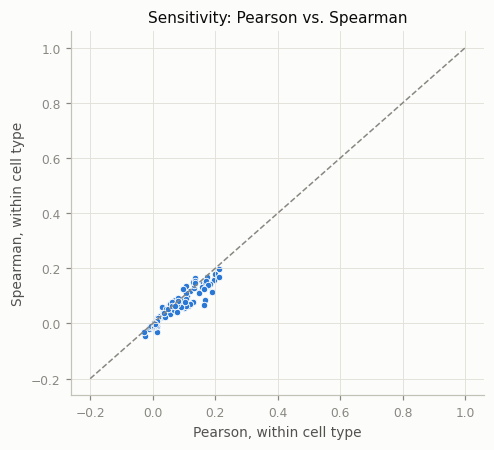

In [10]:
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([-0.2, 1], [-0.2, 1], color=P.MUTED, lw=1, ls="--")
ax.scatter(res["pearson_within_w"], res["spearman_within_w"], s=18, c=P.BLUE, edgecolors=P.SURFACE, linewidths=0.6)
ax.set_xlabel("Pearson, within cell type"); ax.set_ylabel("Spearman, within cell type")
ax.set_title("Sensitivity: Pearson vs. Spearman")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase2_pearson_vs_spearman.png")
print("Spearman - Pearson (within, weighted), primary: median",
      round((prim["spearman_within_w"] - prim["pearson_within_w"]).median(), 3))

## 6. Mapping diagnostic (not used for selection)

For each protein we correlate the protein with **every** measured gene (all cells) and report
where the mapped RNA ranks. A very poor rank flags a possible mapping error to check by hand.
The six isotype controls bind no human protein; their best gene correlation is a noise
reference.

In [11]:
# log1p CP10k for all genes, in place (raw counts are no longer needed)
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
iso = adt.obsm["ADT_isotype_controls"]
Y = np.hstack([Pm, iso.to_numpy(dtype=np.float32)])
t0 = time.time()
r_genes = correlate_with_all_genes(rna.X, Y)
print(f"protein x all-gene correlations: {r_genes.shape}, {time.time() - t0:.0f}s")

diag = mapped_gene_rank(r_genes[:, :len(use)], np.asarray(rna.var_names), res["pearson_all"].to_numpy(),
                        use["protein"].tolist())
diag.insert(1, "analysis_set", use["analysis_set"].to_numpy())
diag.insert(2, "genes", use["genes"].to_numpy())
print("mapped gene is the top gene for", (diag["mapped_rank"] == 1).sum(), "of", len(diag), "proteins")
print("mapped rank distribution:"); print(diag["mapped_rank"].describe(percentiles=[.5, .75, .9]).to_string())
diag.sort_values("mapped_rank", ascending=False).head(15)

protein x all-gene correlations: (13953, 123), 11s
mapped gene is the top gene for 7 of 117 proteins
mapped rank distribution:
count     117.000
mean      721.821
std      2232.080
min         1.000
50%        43.000
75%       194.000
90%       801.000
max     12344.000


,protein,analysis_set,genes,mapped_r,mapped_rank,top_gene,top_gene_r
78,CD83,primary,CD83,-0.065,12344,ALAS2,0.248
95,CD115,primary,CSF1R,-0.090,12265,ALAS2,0.615
38,CD103,primary,ITGAE,-0.021,10240,ALAS2,0.237
77,CD163,primary,CD163,-0.016,7703,ALAS2,0.177
7,CD154,primary,CD40LG,-0.025,7413,ALAS2,0.277
43,CD223,primary,LAG3,-0.021,6935,ALAS2,0.191
42,CD152,primary,CTLA4,-0.017,5315,ALAS2,0.310
69,CD42b,primary,GP1BA,0.001,4963,FCN1,0.159
1,CD270,primary,TNFRSF14,0.014,2779,LTB,0.169
2,CD155,primary,PVR,0.081,1475,LYZ,0.402


In [12]:
iso_ref = pd.DataFrame({
    "isotype": iso.columns,
    "best_gene": [rna.var_names[int(np.nanargmax(r_genes[:, len(use) + k]))] for k in range(iso.shape[1])],
    "best_gene_r": np.nanmax(r_genes[:, len(use):], axis=0),
    "max_abs_r": np.nanmax(np.abs(r_genes[:, len(use):]), axis=0),
})
iso_ref

,isotype,best_gene,best_gene_r,max_abs_r
0,Mouse-IgG1,ALAS2,0.204,0.274
1,Mouse-IgG2a,ALAS2,0.187,0.221
2,Mouse-IgG2b,ALAS2,0.153,0.199
3,Rat-IgG2b,ALAS2,0.113,0.157
4,Rat-IgG1,ALAS2,0.112,0.133
5,Rat-IgG2a,ALAS2,0.135,0.152


In [13]:
RESULTS_DIR.mkdir(exist_ok=True)
res.merge(diag.drop(columns=["analysis_set", "genes"]), on="protein").to_csv(
    RESULTS_DIR / "phase2_protein_rna_correlation.csv", index=False)
iso_ref.to_csv(RESULTS_DIR / "phase2_isotype_noise_reference.csv", index=False)
print("saved")

saved


In [14]:
import resource, platform
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
peak_gb = peak / 1e9 if platform.system() == "Darwin" else peak * 1024 / 1e9
print(f"peak memory of this notebook: {peak_gb:.2f} GB")

peak memory of this notebook: 2.86 GB


## Findings (full data)

**Headline, primary set (110 proteins; median across proteins, IQR in brackets).**

| Correlation of protein with own-gene RNA | Pearson |
|---|---|
| all cells | 0.29 (0.14-0.45) |
| between cell types (means of 42 types with >= 50 cells) | 0.84 (0.61-0.94) |
| within cell type, cell-weighted | 0.07 (0.04-0.12) |
| within cell type, unweighted | 0.10 |
| within cell type x sample (296 groups), cell-weighted | 0.06 |

* Correlation is lower within cell types than across all cells for 100 of 110 proteins (median drop 0.20).
  Most of the own-gene correlation reflects differences **between** cell types; within a cell type the
  gene's RNA in a single cell carries little linear information about that cell's protein level.
* Proteins whose RNA is detected in more cells tend to have a higher within-type correlation
  (Spearman 0.43 across proteins). This fits RNA sampling noise as one cause, but does not prove it.
* **Sample control:** within cell type x sample is almost the same as within cell type (median
  difference 0.006), so sample/site differences do not drive the within-type correlations.
* **Sensitivity:** Spearman gives the same picture (within type: median Spearman - Pearson = -0.005).
* For 58 proteins at least one cell type has an undefined r (gene or protein constant there);
  those groups are skipped and counted.

**Secondary set (reported separately).** CD45 (all isoforms) 0.48 overall, CD45RA 0.14, CD45RO 0.18,
all compared with the same PTPRC RNA. This fits 3' RNA not resolving splice isoforms. CD107a
(mostly intracellular) 0.05. CD16 0.64, CD32 0.48.

**Mapping diagnostic (not used to change mappings).** The mapped gene is the top-correlated gene for
7 of 117 proteins (median rank 43). Over all cells, genes that mark the same cell type correlate as
well as the protein's own gene, so a low rank by itself is expected. Eight proteins have mapped r ~ 0 and rank
> 4,000: CD83, CD115, CD103, CD163, CD154, CD223, CD152, CD42b. All are unambiguous single-gene
mappings, so a mapping error is unlikely; their protein signal may be close to background
(hypothesis). For most of them the best gene correlation (0.16-0.31) is similar to the isotype noise
reference (best gene r 0.11-0.20, max |r| up to 0.27). CD115 is the exception (best gene r 0.61).
No mapping was changed.

**Open observation: ALAS2.** ALAS2, an erythroid gene, is the top gene for all six isotype controls
and for 15 of 117 proteins. Two explanations were checked and **not** supported: a smaller CLR
denominator in erythroid cells (median 4.86 vs 4.78 in myeloid cells), and a higher isotype share
of ADT counts in erythroid cells (0.40% vs 0.45-0.86% in other lineages). It is unexplained.
Separately, the isotype share of ADT counts depends strongly on site (~0.2% at site1, ~1% at site3).

**Scope.** These results cover 117 of 134 proteins (110 in the headline). The 17 proteins without a
measured gene may differ systematically, so the numbers do not generalize to the full panel.

Peak memory 2.9 GB, runtime < 1 min.